# Metamodel case generation

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`tp`, `wd`, `ds`, `zs`).
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from `Samoa.json` → `simulations`.

In [1]:
from utils.config import PATHS, SIMULATIONS, goals_for_snapwave, load_goals, resolve
from utils.simulation import lhs_cases as sim
from utils.simulation.snapwave_wrappers import SnapWaveMetaModelWrapper

## Configuration

In [2]:
templates_dir = resolve(SIMULATIONS["metamodel_templates"])
cases_dir = resolve(SIMULATIONS["metamodel_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"samples   : {SIMULATIONS['num_samples_per_goal']} per goal")

goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-metamodel
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Metamodel
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
samples   : 500 per goal


## LHS cases

In [3]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df.head()

,goal,tp,dir,spr,wl
0,1,12.213669,255.248228,18.939314,1.302719
1,1,8.383269,255.032224,13.775162,-2.609729
2,1,6.444611,289.929811,13.077691,0.370466
3,1,5.190768,346.682246,42.685319,3.339651
4,1,7.184247,201.595858,21.310096,2.068328


In [4]:
import numpy as np

# Add a new column called save_map with 5% True
cases_df["save_map"] = np.random.choice(
    [True, False], size=len(cases_df), p=[0.05, 0.95]
)
cases_df.head(20)

,goal,tp,dir,spr,wl,save_map
0,1,12.213669,255.248228,18.939314,1.302719,False
1,1,8.383269,255.032224,13.775162,-2.609729,False
2,1,6.444611,289.929811,13.077691,0.370466,False
3,1,5.190768,346.682246,42.685319,3.339651,False
4,1,7.184247,201.595858,21.310096,2.068328,False
5,1,11.618990,165.107909,38.181303,-0.755730,False
6,1,10.493074,173.127316,21.632372,-1.529876,False
7,1,2.591502,311.425738,27.794586,-1.373622,False
8,1,10.138542,307.402811,10.274056,1.891158,False
9,1,4.274891,299.293740,10.375578,-1.358873,False


In [5]:
cases_df.groupby(["goal", "save_map"])[["tp"]].count()

tp
goal save_map     
1    False     476
     True       24
2    False     474
     True       26
3    False     474
     True       26
4    False     479
     True       21
5    False     476
     True       24
6    False     472
     True       28
7    False     469
     True       31
8    False     468
     True       32
9    False     468
     True       32
10   False     474
     True       26
11   False     479
     True       21
12   False     464
     True       36
13   False     479
     True       21
14   False     478
     True       22
15   False     468
     True       32
16   False     474
     True       26

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + direction-range bars per goal; right side = text summary.
Review this before `build_cases()`.

In [6]:
wrapper = SnapWaveMetaModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-07-28 10:06:33,243 - SnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-07-28 10:06:33,244 - SnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-07-28 10:06:33,244 - SnapWaveMetaModelWrapper - WARNING - Parameter dir is not in the default_parameters
2026-07-28 10:06:33,244 - SnapWaveMetaModelWrapper - WARNING - Parameter spr is not in the default_parameters
2026-07-28 10:06:33,245 - SnapWaveMetaModelWrapper - WARNING - Parameter wl is not in the default_parameters
2026-07-28 10:06:33,245 - SnapWaveMetaModelWrapper - WARNING - Parameter save_map is not in the default_parameters


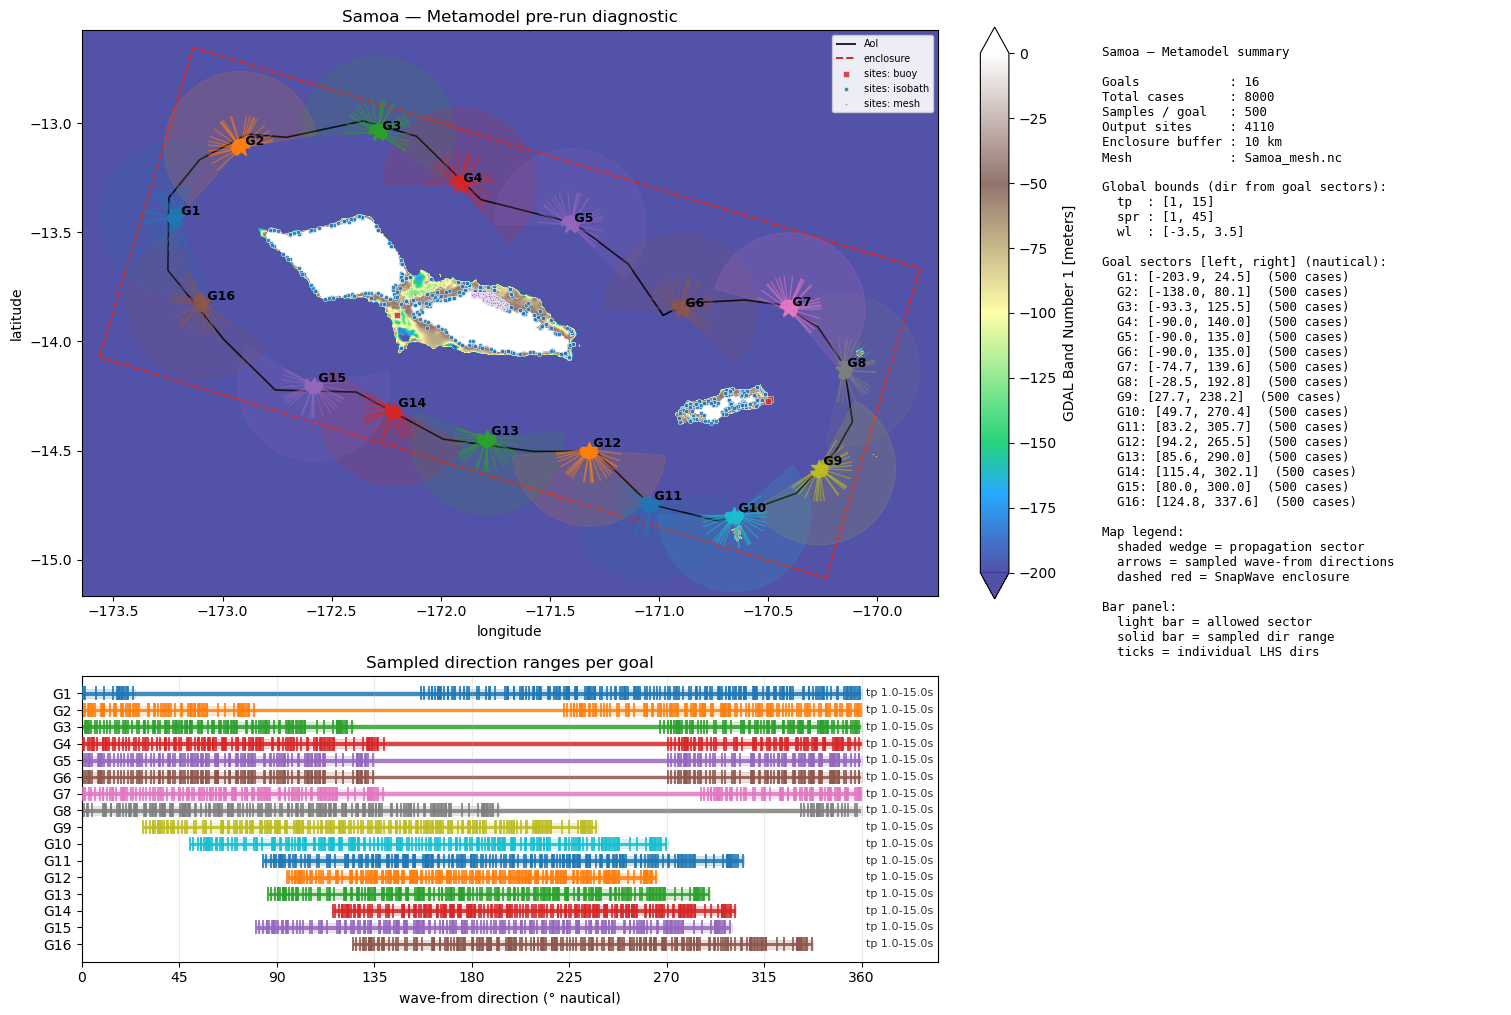

In [7]:
fig = wrapper.plot_configuration()
# fig.savefig("metamodel_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [8]:
wrapper.load_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [16]:
wrapper.run_cases_in_background(
    launcher="default", num_workers=2, cases_to_run=[3077, 5946]
)

2026-07-28 10:09:32,761 - SnapWaveMetaModelWrapper - WARNING - Cases to run was specified, so just [3077, 5946] will be run.


In [17]:
cases_status = wrapper.monitor_cases(value_counts="simple")
cases_status

Status  
FINISHED    8000
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map (or overview fallback)
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

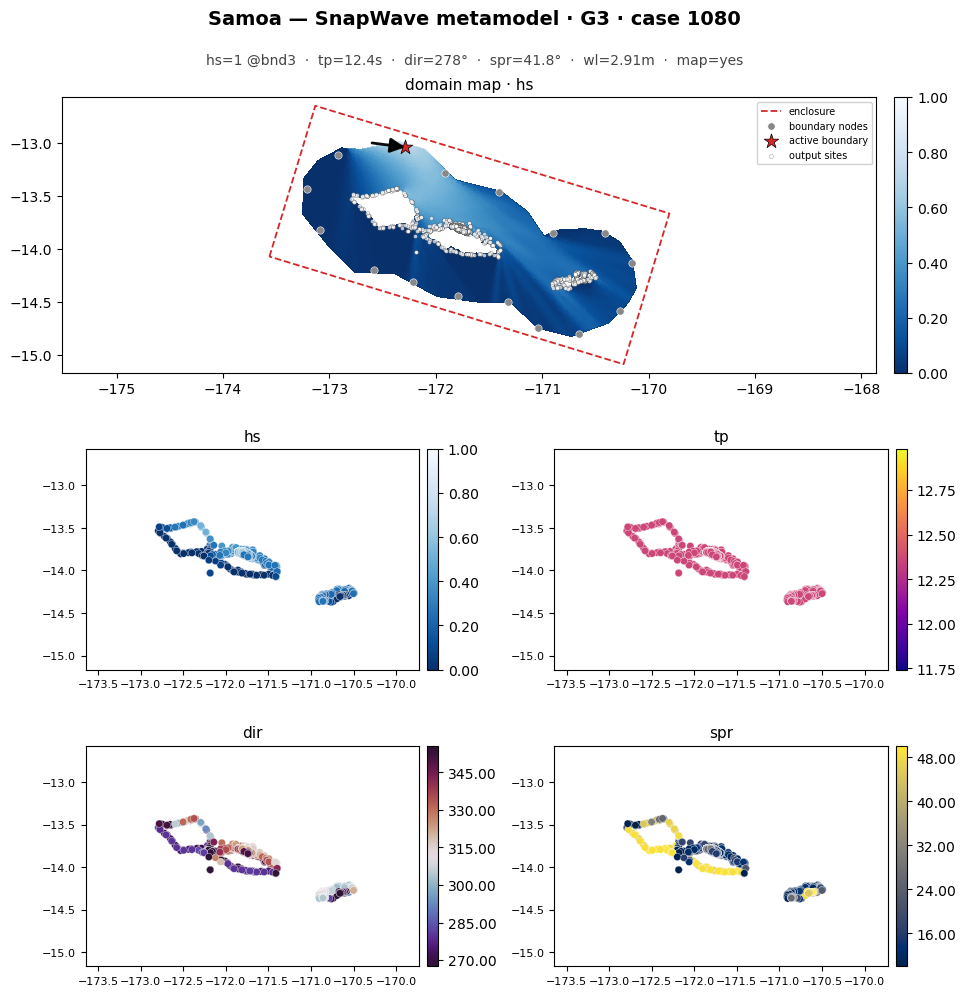

In [19]:
from utils.viz.snapwave_case_plots import CasePlotStyle

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
wrapper.plot_case(goal=3, case_num=1080, style=style);

In [20]:
wrapper.postprocess_cases()

'Done'